# 수업 중 문제풀이: 1D 지하수 흐름의 유한차분
## 이름: _김태연  학번: 202001192

**수업 전 준비**: `FD_explicit_implicit.ipynb` 1~5절을 읽고 한 번 실행해 볼 것.

**수업 시간**: 아래 과제 0~5를 순서대로 풉니다. 옆 사람과 상의해도 되지만 제출은 각자 합니다.

**제출**: 수업 종료 시 파일 이름을 `학번_이름_inclass.ipynb` 로 바꾸고, **Kernel → Restart & Run All** 이 오류 없이 끝나는 상태로 LMS에 올립니다. 미완성이어도 그 시점까지 제출합니다. 이 노트북은 완성도가 아니라 **시도와 근거**로 평가합니다.

**자동 체크**: 과제마다 `check_...()` 셀이 있습니다. PASS 가 나오면 다음으로, FAIL 이면 메시지를 읽고 고치세요. 체크 셀은 수정하지 마세요.

**중간고사와의 관계**: 중간고사(take-home)는 이 노트북과 같은 구조로, 같은 개인 파라미터 규칙을 씁니다. 여기서 막히는 곳이 시험에서도 막히는 곳입니다.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.6,
                     "font.family": "sans-serif",
                     "font.sans-serif": ["Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic", "DejaVu Sans"],
                     "axes.unicode_minus": False, "mathtext.fontset": "dejavusans"})
C_EXP, C_IMP, C_ANA = "#2a78d6", "#eb6834", "#222222"

# ---------- 공통 (수정하지 말 것) ----------
Ss, h0, T = 1e-4, 100.0, 100.0

def make_grid(L, dx, dt):
    nx = int(round(L/dx)) + 1
    nt = int(round(T/dt))
    return np.linspace(0, L, nx), np.arange(nt+1)*dt, nx, nt

def h_analytical(x, t, L, D, n_terms=300):
    # 양끝 0 m, 초기 h0 균일
    x = np.asarray(x, float); h = np.zeros_like(x)
    for m in range(1, 2*n_terms, 2):
        h += 4*h0/(m*np.pi) * np.exp(-(m*np.pi/L)**2*D*t) * np.sin(m*np.pi*x/L)
    return h if h.ndim else float(h)

def rms_vs_analytical(x, t, h, L, D, tt):
    n = int(round(tt/(t[1]-t[0])))
    return float(np.sqrt(np.mean((h[n] - h_analytical(x, tt, L, D))**2)))

def _report(ok, msg):
    print(("PASS  " if ok else "FAIL  ") + msg)
    return ok
print("준비 완료")


준비 완료


## 과제 0. 읽기 확인

강의 노트북을 읽었으면 코드 없이 답할 수 있는 질문입니다. 아래 markdown 셀을 더블클릭해서 **한 문장씩** 쓰세요.

1. $r = D\,\Delta t/\Delta x^2$ 은 물리적으로 무엇을 뜻하는가?
2. explicit 과 implicit 에서 "한 시간단계에 풀어야 하는 미지수의 개수"는 각각 몇 개인가? (내부 절점 수를 $N$ 이라 할 때)
3. 해석해의 Fourier 급수에서 짝수 $m$ 항이 사라지는 이유는?


**답 0-1:** 한 시간단계 동안 수두 교란이 한 격자 간격을 얼마나 지나가는가

**답 0-2:** 내부 절점이 $N$개일 때 explicit은 각 절점에서 미지수 1개를 독립적으로 계산하고, implicit은 미지수 $N$개를 하나의 연립방정식으로 동시에 푼다.

**답 0-3:** 사인값이 0 이기 때문.


## 과제 1. 내 파라미터로 explicit 완성하기

중간고사와 같은 규칙입니다. 학번 끝 두 자리를 $ab$ 라 할 때

- $L = 16 + a$ m, $K = (5 + b)\times 10^{-5}$ m/yr, $S_s = 10^{-4}$ 1/m, $h_0 = 100$ m, 양끝 0 m, 100년.

**1-1.** 아래 셀에 본인 학번을 넣고 $L, K, D$ 와 $\Delta x = 1$ m 일 때의 $\Delta t_{max}$ 를 출력하세요.


In [2]:
STUDENT_ID = "202001192"      # TODO: 본인 학번 (문자열)

a, b = int(STUDENT_ID[-2]), int(STUDENT_ID[-1])
L = 16 + a                        # TODO
K = (5+b)*1e-5                         # 학번 끝자리 b에 따른 수리전도도
D = K/Ss
dx = 1.0

dt_max = dx**2 / (2*D)                   # TODO: Δx = 1 m 일 때 explicit 안정 한계
print(f"L = {L} m, K = {K:.1e} m/yr, D = {D:.2f} m²/yr, Δt_max(Δx=1) = {dt_max:.4f} yr")


L = 25 m, K = 7.0e-05 m/yr, D = 0.70 m²/yr, Δt_max(Δx=1) = 0.7143 yr


**1-2.** explicit 솔버의 핵심 한 줄을 완성하세요. 강의 노트북 3절의 식
$h_i^{n+1} = r\,h_{i-1}^n + (1-2r)\,h_i^n + r\,h_{i+1}^n$ 을 numpy 슬라이싱으로 씁니다.


In [3]:
def solve_explicit(L, D, dx, dt):
    x, t, nx, nt = make_grid(L, dx, dt)
    r = D*dt/dx**2
    h = np.zeros((nt+1, nx))
    h[0, 1:-1] = h0                       # 초기조건 (경계는 0)
    for n in range(nt):
        h[n+1, 1:-1] = r*h[n, :-2] + (1-2*r)*h[n, 1:-1] + r*h[n, 2:]
    return x, t, h, r


In [4]:
# ---- 체크 1 (수정 금지) ----
def check_explicit():
    x, t, h, r = solve_explicit(L, D, 1.0, 0.5*dt_max)
    ok1 = _report(abs(r - 0.25) < 1e-9, f"r = {r:.3f} (기대 0.25)")
    e = rms_vs_analytical(x, t, h, L, D, 10)
    ok2 = _report(e < 0.5, f"t=10 yr 해석해와의 RMS = {e:.3f} m (기대 < 0.5)")
    ok3 = _report(np.all(h >= -1e-9) and np.all(h <= h0 + 1e-9), "수두가 0~100 m 범위 안에 있음")
    return ok1 and ok2 and ok3
check_explicit()


PASS  r = 0.250 (기대 0.25)
PASS  t=10 yr 해석해와의 RMS = 0.238 m (기대 < 0.5)
PASS  수두가 0~100 m 범위 안에 있음


np.True_

**1-3. 예측 먼저.** 아래 셀을 실행하기 **전에** 이 markdown 셀에 쓰세요.
$\Delta t = 0.9\,\Delta t_{max}$ 와 $1.05\,\Delta t_{max}$ 로 t = 30년까지 계산하면 각각 어떤 모양이 나올지 한 문장씩, 그리고 그렇게 생각한 이유(가중치 $1-2r$ 의 부호)를 쓰세요.

**예측 (0.9):** 수두가 부드럽게 안정되는 모양

**예측 (1.05):** 수두가 진동하는 모양

**이유:** 0.9 의 경우 가중치가 양수지만 1.05 의 경우 음수로 나타날 것이기 때문.


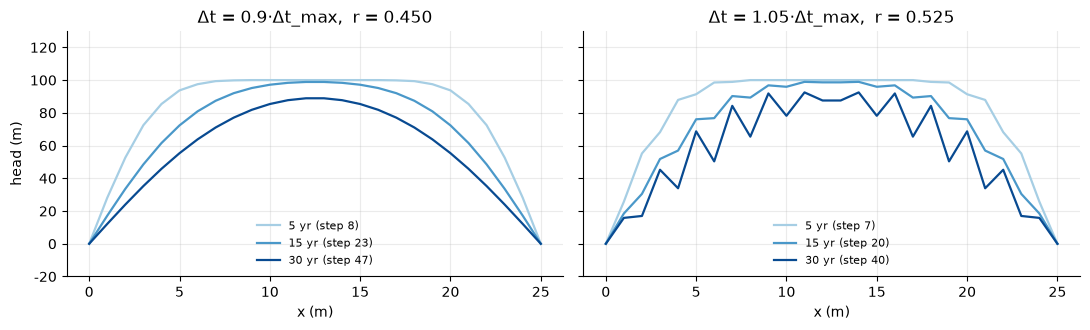

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, f in zip(axes, [0.9, 1.05]):
    x, t, h, r = solve_explicit(L, D, 1.0, f*dt_max)
    for tt, c in [(5, 0.35), (15, 0.6), (30, 0.9)]:
        n = int(round(tt/(f*dt_max)))
        ax.plot(x, h[n], color=plt.cm.Blues(c), label=f"{tt} yr (step {n})")
    ax.set_title(f"Δt = {f}·Δt_max,  r = {r:.3f}"); ax.set_xlabel("x (m)"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("head (m)"); axes[0].set_ylim(-20, 130)
plt.tight_layout(); plt.show()


**1-4.** 예측과 실제가 달랐다면 무엇이 달랐나요? 같았다면, 1.05 쪽에서 진동이 **어느 절점부터** 시작했는지 쓰세요.

**답:** 진동이 경계점의 바로 안쪽 절점부터 시작된다.


## 과제 2. implicit 행렬 완성하기

**2-1.** 삼중대각 행렬 $\mathbf{A}$ 를 만드는 함수를 완성하세요. 강의 노트북 4절:
$-r\,h_{i-1}^{n+1} + (1+2r)\,h_i^{n+1} - r\,h_{i+1}^{n+1} = h_i^n$


In [6]:
def build_A(r, n_unknown):
    main = np.full(n_unknown, 1 + 2*r)
    off  = np.full(n_unknown-1, -r)
    return np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

def solve_implicit(L, D, dx, dt):
    x, t, nx, nt = make_grid(L, dx, dt)
    r = D*dt/dx**2
    A = build_A(r, nx-2)
    h = np.zeros((nt+1, nx))
    h[0, 1:-1] = h0
    for n in range(nt):
        h[n+1, 1:-1] = np.linalg.solve(A, h[n, 1:-1])
    return x, t, h, r

print(np.round(build_A(0.1, 4), 2))


[[ 1.2 -0.1  0.   0. ]
 [-0.1  1.2 -0.1  0. ]
 [ 0.  -0.1  1.2 -0.1]
 [ 0.   0.  -0.1  1.2]]


In [7]:
# ---- 체크 2 (수정 금지) ----
def check_implicit():
    A = build_A(0.1, 4)
    ok1 = _report(np.allclose(np.diag(A), 1.2) and np.allclose(np.diag(A, 1), -0.1) and np.allclose(np.diag(A, -1), -0.1),
                  "A 의 대각 = 1+2r, 비대각 = -r")
    x, t, h, r = solve_implicit(L, D, 1.0, 2*dt_max)      # explicit 이면 터지는 Δt
    e = rms_vs_analytical(x, t, h, L, D, 10)
    ok2 = _report(e < 1.5, f"Δt = 2·Δt_max (r = {r:.2f}) 에서 t=10 yr RMS = {e:.3f} m (기대 < 1.5, 발산 없음)")
    return ok1 and ok2
check_implicit()


PASS  A 의 대각 = 1+2r, 비대각 = -r
PASS  Δt = 2·Δt_max (r = 1.00) 에서 t=10 yr RMS = 0.989 m (기대 < 1.5, 발산 없음)


True

**2-2.** 같은 $\Delta x = 1$ m 에서 $\Delta t$ 를 $\Delta t_{max}$, $5\,\Delta t_{max}$, $20\,\Delta t_{max}$ 로 바꿔 t = 10 yr 의 RMS 오차를 출력하고, 아래 두 문장을 완성하세요.


In [8]:
for f in [1, 5, 20]:
    x, t, h, r = solve_implicit(L, D, 1.0, f*dt_max)
    n10 = int(round(10/(t[1]-t[0])))
    error = rms_vs_analytical(x, t, h, L, D, 10)
    print(f"Δt = {f:>2}·Δt_max, r = {r:>4.1f}, nearest t = {t[n10]:>6.3f} yr, RMS = {error:.3f} m")


Δt =  1·Δt_max, r =  0.5, nearest t = 10.000 yr, RMS = 0.527 m
Δt =  5·Δt_max, r =  2.5, nearest t = 10.714 yr, RMS = 1.653 m
Δt = 20·Δt_max, r = 10.0, nearest t = 14.286 yr, RMS = 4.280 m


**안정성:** implicit 은 $r$ 이 0.5 보다 커도 발산하지 않는다. 근거: 발산하지 않음을 확인함.

**정확도:** 그러나 $\Delta t$ 를 키우면 오차는 증가한다. 근거: 오차의 증가를 확인함.


## 과제 3. 오차는 어디서 오는가

$\Delta x$ 와 $\Delta t$ 중 **어느 쪽을 줄여야** 오차가 줄어드는지 실험으로 알아냅니다. explicit 으로, t = 10 yr 의 RMS 오차를 2×3 표로 만드세요.

- 행: $\Delta x$ = 1.0, 0.5 m
- 열: $\Delta t$ = 0.5, 0.1, 0.02 × ($\Delta x$ = 1 일 때의 $\Delta t_{max}$)

주의: $\Delta x = 0.5$ 에서 어떤 $\Delta t$ 는 불안정합니다. 그 칸은 `unstable` 로 표시하세요 (계산해서 터지는 걸 확인해도 되고, $r$ 로 미리 판단해도 됩니다).


In [9]:
dts = [0.5*dt_max, 0.1*dt_max, 0.02*dt_max]
print(f"{'Δx':>5} | " + " ".join(f"{'Δt='+format(dt_,'.4f'):>12}" for dt_ in dts))
for dx in [1.0, 0.5]:
    row = []
    for dt_ in dts:
        r = D*dt_/dx**2
        if r <= 0.5:
            x, t, h, _ = solve_explicit(L, D, dx, dt_)
            error = rms_vs_analytical(x, t, h, L, D, 10)
            row.append(f"{error:.3f}")
        else:
            row.append("unstable")
    print(f"{dx:>5} | " + " ".join(f"{v:>12}" for v in row))


   Δx |    Δt=0.3571    Δt=0.0714    Δt=0.0143
  1.0 |        0.238        0.110        0.112
  0.5 |     unstable        0.049        0.027


**3-1.** 표에서 $\Delta t$ 를 1/25 로 줄였을 때와 $\Delta x$ 를 1/2 로 줄였을 때, 오차는 각각 몇 배로 줄었나요? 어느 쪽이 "바닥"을 만들고 있나요?

**답:** Δx=1 m에서 Δt를 1/25로 줄이면 RMS 오차는 0.238 m에서 0.112 m로 약 2.1배 감소했다. 가장 작은 Δt에서 Δx를 절반으로 줄이면 0.112 m에서 0.027 m로 약 4.1배 감소했다. Δt를 더 줄여도 오차가 약 0.11 m에서 감소하지 않으므로 공간 이산화 오차가 바닥을 만들고 있다.

**3-2.** $\Delta x = 0.5$ 에서 불안정했던 칸을 implicit 으로 바꾸면 값이 얼마가 되나요? (아래 셀에 계산) 그 값이 $\Delta x = 1$ 행의 같은 열보다 작은지 큰지, 왜 그런지 한 문장.

**답:**  implicit으로 계산한 RMS 오차는 약 0.258 m이며, Δx=1 m인 같은 열의 0.238 m보다 크다. 공간 격자는 더 촘촘하지만 Δt가 커서 implicit의 시간 오차가 지배하기 때문이다.


In [10]:
# 3-2: 표에서 unstable인 칸(Δx=0.5, 첫 번째 Δt)을 implicit으로 계산
dx_32 = 0.5
dt_32 = dts[0]
x_32, t_32, h_32, r_32 = solve_implicit(L, D, dx_32, dt_32)
error_32 = rms_vs_analytical(x_32, t_32, h_32, L, D, 10)
print(f"Δx = {dx_32}, Δt = {dt_32:.4f}, r = {r_32:.1f}, implicit RMS = {error_32:.3f} m")


Δx = 0.5, Δt = 0.3571, r = 1.0, implicit RMS = 0.258 m


## 과제 4. 틀린 줄 하나 찾기

아래 코드는 위쪽 경계 수두를 20 m, 아래쪽을 0 m 로 두고 implicit 으로 푼 것입니다. 오류 없이 실행되고 그림도 나옵니다. 그러나 **한 줄이 틀렸습니다.**

1. 먼저 실행해 보고, 그림의 **어디가 물리적으로 이상한지** 쓰세요. (힌트: 시간이 충분히 지나면 수두 단면은 어떤 모양이어야 하는가?)
2. 틀린 줄을 찾아 고치고, 고친 뒤의 그림으로 이상한 점이 사라졌음을 보이세요.

중간고사 문제 3은 이것의 확장판(오류 5개)입니다.


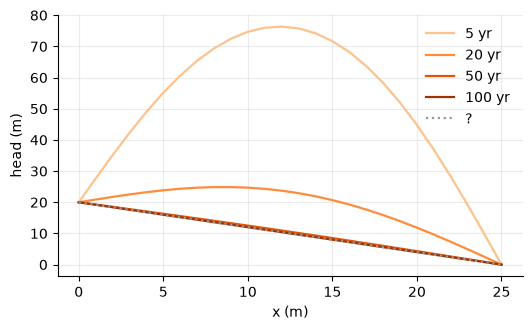

In [18]:
h_top = 20.0

def solve_implicit_bc(L, D, dx, dt, h_top):
    x, t, nx, nt = make_grid(L, dx, dt)
    r = D*dt/dx**2
    A = build_A(r, nx-2)
    h = np.zeros((nt+1, nx))
    h[0, 1:-1] = h0
    h[:, 0] = h_top
    for n in range(nt):
        b = h[n, 1:-1].copy()
        b[0] += r*h_top
        h[n+1, 1:-1] = np.linalg.solve(A, b)
    return x, t, h, r

x, t, h, r = solve_implicit_bc(L, D, 1.0, 0.5, h_top)
fig, ax = plt.subplots(figsize=(6, 3.4))
for tt, c in [(5, 0.3), (20, 0.5), (50, 0.7), (100, 0.9)]:
    ax.plot(x, h[int(round(tt/0.5))], color=plt.cm.Oranges(c), label=f"{tt} yr")
ax.plot(x, h_top*(1 - x/L), color="#999", ls=":", label="?")
ax.set_xlabel("x (m)"); ax.set_ylabel("head (m)"); ax.legend(frameon=False); plt.show()


**이상한 점:** 시간이 지나면 직선과 비슷하게 수렴해야 할 수두가 0으로 수렴한다.

**틀린 줄과 이유:**  `b = h[n, 1:-1].copy()` 다음에 첫 내부 절점에 대한 위쪽 경계 기여 `b[0] += r*h_top`이 빠져 있다. 이 항이 없으면 내부 연립방정식에서는 위쪽 경계를 0 m처럼 취급한다.

**고친 뒤 확인:** 경계 기여를 추가하면 왼쪽 경계와 내부 수두가 부드럽게 연결된다.


In [19]:
# ---- 체크 4 (수정 금지): 고친 함수가 정상상태 직선으로 가는지 ----
def check_bc():
    x, t, h, r = solve_implicit_bc(L, D, 1.0, 0.5, 20.0)
    # 충분히 긴 시간: 저장된 T=100 대신 내부적으로 2000년까지 더 돌림
    A = build_A(r, len(x)-2); hh = h[-1].copy()
    for _ in range(int(1900/0.5)):
        b = hh[1:-1].copy(); b[0] += r*20.0
        hh[1:-1] = np.linalg.solve(A, b)
    dev = np.abs(hh - 20.0*(1 - x/L)).max()
    return _report(dev < 0.5, f"2000년 후 정상상태 직선과의 최대 차이 = {dev:.3f} m (기대 < 0.5)")
check_bc()


PASS  2000년 후 정상상태 직선과의 최대 차이 = 0.000 m (기대 < 0.5)


np.True_

## 과제 5. 제출 전

**5-1. 한 줄 성찰:** 오늘 과제 중 예상과 가장 달랐던 결과 하나.

**답:** ai에게 코드 작성을 요청해도 충분히 틀릴 수 있다.

**5-2. LLM 사용 기록:** 오늘 LLM(ChatGPT, Claude 등)을 썼다면 무엇을 물었고 답을 어떻게 확인했는지 한 줄. 안 썼으면 "사용하지 않음". (중간고사에서는 이 기록이 필수입니다.)

**답:** 코드 작성을 요청하고 답을 원본 노트북 코드와 대조함. 

**제출 체크리스트**
- [ ] 맨 위에 이름·학번을 썼다
- [ ] Kernel → Restart & Run All 이 오류 없이 끝난다
- [ ] 체크 셀 1, 2, 4 가 모두 PASS 다 (FAIL 이어도 제출은 하되, 어디서 막혔는지 5-1 에 적는다)
- [ ] 파일 이름이 `학번_이름_inclass.ipynb` 다
